# LAB 15: PyTorch, Autograd and Neural Networks

**Course:** ICD341 – Advanced Statistical Computing  
**Institution:** Mulungushi University  
**School:** School of Natural and Applied Sciences  
**Department:** Mathematics and Statistics

## Introduction

PyTorch is an open-source machine learning framework used for developing and training deep learning models. It provides tools for working with tensors, performing mathematical operations and building neural networks.

One of its important features is **Autograd**, which automatically calculates gradients (derivatives) of mathematical functions. These gradients are essential when training neural networks through optimisation algorithms such as gradient descent.

## Objectives

By the end of this laboratory, we should be able to:

1. Understand and create PyTorch tensors.
2. Perform mathematical operations using tensors.
3. Use Autograd to calculate derivatives automatically.
4. Build a simple neural network using PyTorch.
5. Train a neural network using gradient descent.
6. Visualise the predictions of a trained neural network.

## Software and Libraries

- Python
- PyTorch
- NumPy
- Matplotlib
- Jupyter Notebook

In [6]:
import sys

print("Python executable:", sys.executable)
print("Python version:", sys.version)

Python executable: c:\Users\asus\.conda\envs\icd341\python.exe
Python version: 3.12.14 | packaged by Anaconda, Inc. | (main, Aug 27 2026, 14:37:13) [MSC v.1942 64 bit (AMD64)]


In [7]:
import torch

print("PyTorch version: - Lab15_PyTorch_Autograd_Neural_Networks.ipynb:3", torch.__version__)
print("CUDA available: - Lab15_PyTorch_Autograd_Neural_Networks.ipynb:4", torch.cuda.is_available())

PyTorch version: - Lab15_PyTorch_Autograd_Neural_Networks.ipynb:3 2.14.1+cu130
CUDA available: - Lab15_PyTorch_Autograd_Neural_Networks.ipynb:4 True


## Practical Exercise 1: Introduction to PyTorch Tensors

A tensor is a multidimensional array used by PyTorch to store and manipulate numerical data.

Tensors are similar to NumPy arrays but have additional capabilities, including GPU acceleration and automatic differentiation.

PyTorch supports:
- Scalar tensors (0 dimensions).
- Vector tensors (1 dimension).
- Matrix tensors (2 dimensions).
- Higher-dimensional tensors.

In this exercise, we create different types of tensors and examine their properties.

In [8]:
import torch

scalar = torch.tensor(10)

print("Scalar Tensor:")
print(scalar)

print("Dimensions:", scalar.ndim)
print("Shape:", scalar.shape)

Scalar Tensor:
tensor(10)
Dimensions: 0
Shape: torch.Size([])


In [9]:
vector = torch.tensor([10, 20, 30, 40, 50])

print("Vector Tensor: - Lab15_PyTorch_Autograd_Neural_Networks.ipynb:3")
print(vector)

print("Dimensions: - Lab15_PyTorch_Autograd_Neural_Networks.ipynb:6", vector.ndim)
print("Shape: - Lab15_PyTorch_Autograd_Neural_Networks.ipynb:7", vector.shape)

Vector Tensor: - Lab15_PyTorch_Autograd_Neural_Networks.ipynb:3
tensor([10, 20, 30, 40, 50])
Dimensions: - Lab15_PyTorch_Autograd_Neural_Networks.ipynb:6 1
Shape: - Lab15_PyTorch_Autograd_Neural_Networks.ipynb:7 torch.Size([5])


In [10]:
matrix = torch.tensor([
    [1, 2, 3],
    [4, 5, 6]
])

print("Matrix Tensor: - Lab15_PyTorch_Autograd_Neural_Networks.ipynb:6")
print(matrix)

print("Dimensions: - Lab15_PyTorch_Autograd_Neural_Networks.ipynb:9", matrix.ndim)
print("Shape: - Lab15_PyTorch_Autograd_Neural_Networks.ipynb:10", matrix.shape)

Matrix Tensor: - Lab15_PyTorch_Autograd_Neural_Networks.ipynb:6
tensor([[1, 2, 3],
        [4, 5, 6]])
Dimensions: - Lab15_PyTorch_Autograd_Neural_Networks.ipynb:9 2
Shape: - Lab15_PyTorch_Autograd_Neural_Networks.ipynb:10 torch.Size([2, 3])


In [11]:
random_tensor = torch.rand(3, 3)

print("Random Tensor: - Lab15_PyTorch_Autograd_Neural_Networks.ipynb:3")
print(random_tensor)

print("Shape: - Lab15_PyTorch_Autograd_Neural_Networks.ipynb:6", random_tensor.shape)

Random Tensor: - Lab15_PyTorch_Autograd_Neural_Networks.ipynb:3
tensor([[0.0431, 0.1531, 0.9679],
        [0.0605, 0.0812, 0.2723],
        [0.2170, 0.5240, 0.6497]])
Shape: - Lab15_PyTorch_Autograd_Neural_Networks.ipynb:6 torch.Size([3, 3])


## Practical Exercise 2: Mathematical Operations on Tensors

PyTorch supports several mathematical operations on tensors, including:

- Addition
- Subtraction
- Multiplication
- Division

These operations can be performed element-wise when tensors have compatible shapes.

In this exercise, we demonstrate these operations using two tensors.

In [12]:
a = torch.tensor([10, 20, 30, 40])
b = torch.tensor([2, 4, 5, 8])

print("Tensor A:", a)
print("Tensor B:", b)

Tensor A: tensor([10, 20, 30, 40])
Tensor B: tensor([2, 4, 5, 8])


In [13]:
addition = a + b

print("Addition: - Lab15_PyTorch_Autograd_Neural_Networks.ipynb:3", addition)

Addition: - Lab15_PyTorch_Autograd_Neural_Networks.ipynb:3 tensor([12, 24, 35, 48])


In [14]:
subtraction = a - b

print("Subtraction: - Lab15_PyTorch_Autograd_Neural_Networks.ipynb:3", subtraction)

Subtraction: - Lab15_PyTorch_Autograd_Neural_Networks.ipynb:3 tensor([ 8, 16, 25, 32])


In [15]:
multiplication = a * b

print("Multiplication: - Lab15_PyTorch_Autograd_Neural_Networks.ipynb:3", multiplication)

Multiplication: - Lab15_PyTorch_Autograd_Neural_Networks.ipynb:3 tensor([ 20,  80, 150, 320])


In [16]:
division = a / b

print("Division: - Lab15_PyTorch_Autograd_Neural_Networks.ipynb:3", division)

Division: - Lab15_PyTorch_Autograd_Neural_Networks.ipynb:3 tensor([5., 5., 6., 5.])


In [17]:
print("Sum of A: - Lab15_PyTorch_Autograd_Neural_Networks.ipynb:1", torch.sum(a).item())
print("Mean of A: - Lab15_PyTorch_Autograd_Neural_Networks.ipynb:2", torch.mean(a.float()).item())

Sum of A: - Lab15_PyTorch_Autograd_Neural_Networks.ipynb:1 100
Mean of A: - Lab15_PyTorch_Autograd_Neural_Networks.ipynb:2 25.0


## Practical Exercise 3: Automatic Differentiation Using Autograd

Autograd is PyTorch's automatic differentiation engine.

It calculates gradients automatically by tracking mathematical operations performed on tensors.

When a tensor is created with `requires_grad=True`, PyTorch tracks operations involving that tensor so that derivatives can be calculated.

In this exercise, we calculate the derivative of:

\[
y = x^2 + 3x + 2
\]

at:

\[
x = 5
\]

Using differentiation:

\[
\frac{dy}{dx} = 2x + 3
\]

At \(x=5\):

\[
\frac{dy}{dx} = 2(5)+3=13
\]

We will verify this result using PyTorch Autograd.

In [18]:
x = torch.tensor(5.0, requires_grad=True)

print("Input value:", x)
print("Requires gradient:", x.requires_grad)

Input value: tensor(5., requires_grad=True)
Requires gradient: True


In [19]:
y = x**2 + 3*x + 2

print("Output y: - Lab15_PyTorch_Autograd_Neural_Networks.ipynb:3", y)

Output y: - Lab15_PyTorch_Autograd_Neural_Networks.ipynb:3 tensor(42., grad_fn=<AddBackward0>)


In [20]:
y.backward()

print("Gradient dy/dx: - Lab15_PyTorch_Autograd_Neural_Networks.ipynb:3", x.grad)

Gradient dy/dx: - Lab15_PyTorch_Autograd_Neural_Networks.ipynb:3 tensor(13.)


## Practical Exercise 4: Building a Simple Neural Network

A neural network is a machine learning model inspired by the structure of the human brain.

It consists of interconnected artificial neurons that learn patterns from data.

In this exercise, we will build a simple neural network using PyTorch.

The network will learn the relationship:

\[
y = 2x + 1
\]

We will:
1. Generate training data.
2. Define a neural network.
3. Select a loss function.
4. Select an optimisation algorithm.
5. Train the network.
6. Evaluate its predictions.

In [21]:
import matplotlib.pyplot as plt

# Generate input data
X = torch.linspace(0, 10, 100).reshape(-1, 1)

# Generate corresponding output data
Y = 2 * X + 1

print("Input shape:", X.shape)
print("Output shape:", Y.shape)

print("\nFirst five input values:")
print(X[:5])

print("\nFirst five output values:")
print(Y[:5])

Input shape: torch.Size([100, 1])
Output shape: torch.Size([100, 1])

First five input values:
tensor([[0.0000],
        [0.1010],
        [0.2020],
        [0.3030],
        [0.4040]])

First five output values:
tensor([[1.0000],
        [1.2020],
        [1.4040],
        [1.6061],
        [1.8081]])


In [22]:
import matplotlib.pyplot as plt

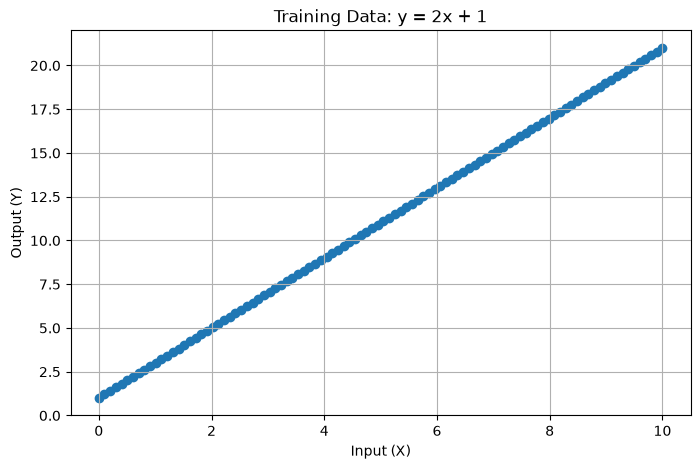

In [23]:
plt.figure(figsize=(8, 5))

plt.scatter(X.numpy(), Y.numpy())

plt.xlabel("Input (X)")
plt.ylabel("Output (Y)")
plt.title("Training Data: y = 2x + 1")

plt.grid(True)
plt.show()

### Defining the Neural Network Architecture

We will use PyTorch's `nn.Linear` layer to create a simple neural network.

The layer performs the mathematical operation:

\[
\hat{y} = wx + b
\]

Where:
- \(w\) represents the weight.
- \(b\) represents the bias.
- \(x\) represents the input.
- \(\hat{y}\) represents the predicted output.

During training, the network will learn the appropriate weight and bias values.

In [24]:
import torch.nn as nn

# Define the neural network
model = nn.Linear(1, 1)

print("Neural Network Architecture:")
print(model)

Neural Network Architecture:
Linear(in_features=1, out_features=1, bias=True)


In [25]:
print("Initial Weight: - Lab15_PyTorch_Autograd_Neural_Networks.ipynb:1")
print(model.weight)

print("\nInitial Bias: - Lab15_PyTorch_Autograd_Neural_Networks.ipynb:4")
print(model.bias)

Initial Weight: - Lab15_PyTorch_Autograd_Neural_Networks.ipynb:1
Parameter containing:
tensor([[-0.3829]], requires_grad=True)

Initial Bias: - Lab15_PyTorch_Autograd_Neural_Networks.ipynb:4
Parameter containing:
tensor([0.1342], requires_grad=True)


In [26]:
sample_input = torch.tensor([[5.0]])

prediction = model(sample_input)

print("Input: - Lab15_PyTorch_Autograd_Neural_Networks.ipynb:5", sample_input.item())
print("Initial Prediction: - Lab15_PyTorch_Autograd_Neural_Networks.ipynb:6", prediction.item())

Input: - Lab15_PyTorch_Autograd_Neural_Networks.ipynb:5 5.0
Initial Prediction: - Lab15_PyTorch_Autograd_Neural_Networks.ipynb:6 -1.7805280685424805


### Configuring the Loss Function and Optimiser

We will use Mean Squared Error (MSE) as our loss function.

MSE calculates the average squared difference between predicted values and actual values.

We will use Stochastic Gradient Descent (SGD) as our optimisation algorithm.

SGD updates the model parameters using the gradients calculated through backpropagation.

Our learning rate will be 0.01.

In [27]:
# Define the loss function
loss_function = nn.MSELoss()

print("Loss function:", loss_function)

Loss function: MSELoss()


In [29]:
%pip install mpmath

   ---------------------------------------- 0.0/567.8 kB ? eta -:--:--
   ---------------------------------------- 0.0/567.8 kB ? eta -:--:--
   ---------------------------------------- 567.8/567.8 kB 2.8 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sympy 1.14.0 requires mpmath<1.4,>=1.1.0, but you have mpmath 1.4.1 which is incompatible.


In [30]:
# Define the optimiser
optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.01
)

print("Optimiser: - Lab15_PyTorch_Autograd_Neural_Networks.ipynb:7", optimizer)

Optimiser: - Lab15_PyTorch_Autograd_Neural_Networks.ipynb:7 SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.01
    maximize: False
    momentum: 0
    nesterov: False
    weight_decay: 0
)


### Training the Neural Network

We will train our neural network for 1000 epochs.

An epoch represents one complete pass through the training dataset.

During each epoch, the network will:

1. Make predictions using the input data.
2. Calculate the loss between predictions and actual values.
3. Clear previously calculated gradients.
4. Perform backpropagation using `loss.backward()`.
5. Update its parameters using `optimizer.step()`.

The objective is to minimise the loss so that the network learns the relationship:

\[
y = 2x + 1
\]

In [31]:
# Train the neural network
epochs = 1000

for epoch in range(epochs):

    # Forward pass
    predictions = model(X)

    # Calculate loss
    loss = loss_function(predictions, Y)

    # Clear previous gradients
    optimizer.zero_grad()

    # Backpropagation
    loss.backward()

    # Update model parameters
    optimizer.step()

    # Display progress every 100 epochs
    if (epoch + 1) % 100 == 0:
        print(f"Epoch [{epoch + 1}/{epochs}], Loss: {loss.item():.6f}")

Epoch [100/1000], Loss: 0.023335
Epoch [200/1000], Loss: 0.008625
Epoch [300/1000], Loss: 0.003188
Epoch [400/1000], Loss: 0.001178
Epoch [500/1000], Loss: 0.000436
Epoch [600/1000], Loss: 0.000161
Epoch [700/1000], Loss: 0.000060
Epoch [800/1000], Loss: 0.000022
Epoch [900/1000], Loss: 0.000008
Epoch [1000/1000], Loss: 0.000003


### Evaluating the Trained Neural Network

After training, we examine the learned weight and bias.

The target relationship is:

\[
y = 2x + 1
\]

Therefore, we expect the trained network to learn:

- Weight approximately equal to 2.
- Bias approximately equal to 1.

If the learned parameters are close to these values, the network has successfully learned the relationship.

In [32]:
print("Learned Weight:", model.weight.item())
print("Learned Bias:", model.bias.item())

Learned Weight: 2.0005147457122803
Learned Bias: 0.996576189994812


### Making Predictions

We now use the trained neural network to predict outputs for new input values.

We use `torch.no_grad()` because we are evaluating the model rather than calculating gradients for further training.

In [33]:
model.eval()

with torch.no_grad():
    test_input = torch.tensor([[2.0], [5.0], [8.0], [10.0]])
    predictions = model(test_input)

print("Test Inputs:")
print(test_input)

print("\nPredicted Outputs:")
print(predictions)

print("\nActual Outputs:")
print(2 * test_input + 1)

Test Inputs:
tensor([[ 2.],
        [ 5.],
        [ 8.],
        [10.]])

Predicted Outputs:
tensor([[ 4.9976],
        [10.9992],
        [17.0007],
        [21.0017]])

Actual Outputs:
tensor([[ 5.],
        [11.],
        [17.],
        [21.]])


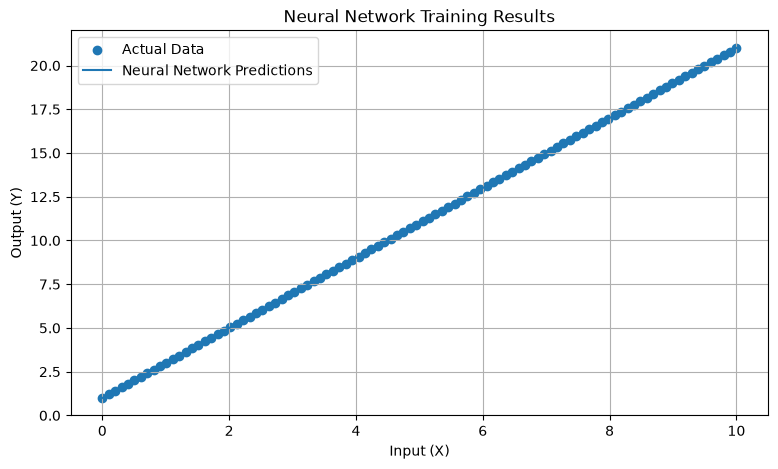

In [34]:
with torch.no_grad():
    predicted_values = model(X)

plt.figure(figsize=(9, 5))

plt.scatter(X.numpy(), Y.numpy(), label="Actual Data")
plt.plot(
    X.numpy(),
    predicted_values.numpy(),
    label="Neural Network Predictions"
)

plt.xlabel("Input (X)")
plt.ylabel("Output (Y)")
plt.title("Neural Network Training Results")
plt.legend()
plt.grid(True)

plt.show()

### Interpretation of Results

The trained neural network successfully learned the mathematical relationship:

\[
y = 2x + 1
\]

The learned weight was approximately 2.0005, while the learned bias was approximately 0.9966.

These values are very close to the expected parameters of 2 and 1.

The network also produced predictions that were almost identical to the actual outputs.

For example, when the input was 5, the predicted output was approximately 10.9992, compared to the actual output of 11.

The visualisation also showed that the predicted line closely followed the original training data.

Therefore, the neural network successfully learned the relationship through backpropagation and gradient descent.

# Conclusion

In this laboratory, we explored PyTorch and its applications in automatic differentiation and neural network development.

We successfully:

1. Created scalar, vector, matrix and random tensors.
2. Performed mathematical operations on tensors.
3. Used PyTorch Autograd to calculate derivatives automatically.
4. Built a simple neural network using the `nn.Linear` layer.
5. Configured Mean Squared Error as the loss function.
6. Used Stochastic Gradient Descent to optimise the network.
7. Trained the neural network using backpropagation.
8. Evaluated predictions and visualised the training results.

The Autograd experiment correctly calculated the derivative of the function at x = 5 as 13.

The neural network also successfully learned the relationship y = 2x + 1, obtaining a weight of approximately 2.0005 and a bias of approximately 0.9966.

Overall, this laboratory demonstrated how PyTorch tensors, automatic differentiation and optimisation techniques can be combined to develop and train neural networks.